In [5]:
!pip install pandas_datareader statsmodels scikit-learn matplotlib xgboost
!pip install --upgrade statsmodels scipy
!pip install pmdarima

   ---------------------------------------- 0.0/711.9 kB ? eta -:--:--
   -------------- ------------------------- 262.1/711.9 kB ? eta -:--:--
   ---------------------------------------- 711.9/711.9 kB 3.3 MB/s eta 0:00:00


c:\Users\oncuy\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


            CPIAUCSL  inflation
DATE                           
2026-05-01   333.979   4.166615
2026-06-01   332.568   3.463531
2026-07-01   332.813   3.303856
2026-08-01   334.131   3.353016
2026-09-01   336.298   3.717251


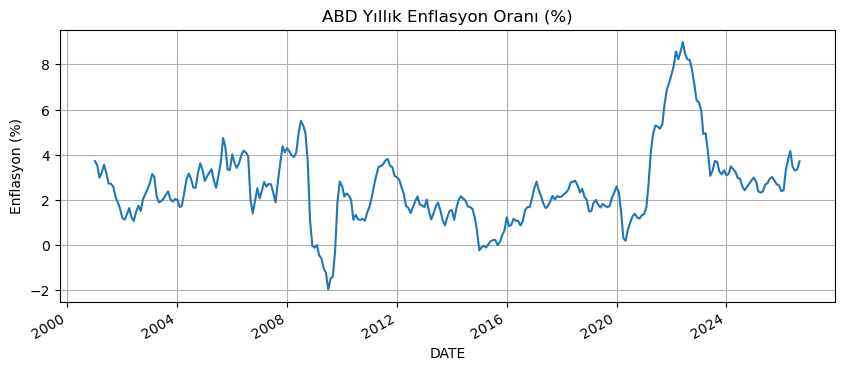

In [2]:
import pandas as pd
import pandas_datareader.data as web
import matplotlib.pyplot as plt

# 1. FRED'den ABD Tüketici Fiyat Endeksi (CPI) verisini çek
df = web.DataReader('CPIAUCSL', 'fred', start='2000-01-01')

# 2. Yıllık enflasyon oranını (%) hesapla
df['inflation'] = df['CPIAUCSL'].pct_change(12) * 100
df = df.dropna()

# 3. Son 5 satırı gör ve grafiği çizdir
print(df.tail())

df['inflation'].plot(figsize=(10, 4), title='ABD Yıllık Enflasyon Oranı (%)')
plt.ylabel('Enflasyon (%)')
plt.grid(True)
plt.show()

c:\Users\oncuy\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\oncuy\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\oncuy\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


ARIMA Test RMSE Hatası: 0.6851


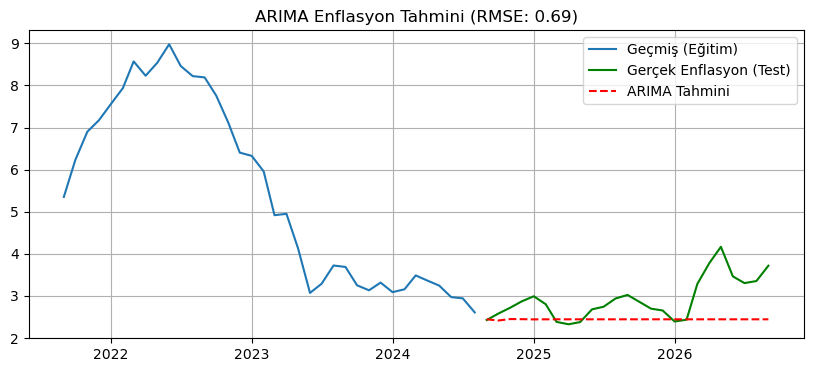

In [3]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import root_mean_squared_error
import numpy as np

# 1. Veriyi Eğitim (Train) ve Test olarak böl (Son 24 ay test olsun)
train = df['inflation'][:-24]
test = df['inflation'][-24:]

# 2. ARIMA Modelini Kur ve Eğit (p=2, d=1, q=2 klasik bir başlangıçtır)
model_arima = ARIMA(train, order=(2, 1, 2))
fitted_arima = model_arima.fit()

# 3. Son 24 ay için tahmin yap
forecast_arima = fitted_arima.forecast(steps=24)

# 4. Hata oranını (RMSE) hesapla
rmse_arima = root_mean_squared_error(test, forecast_arima)
print(f"ARIMA Test RMSE Hatası: {rmse_arima:.4f}")

# 5. Gerçek vs ARIMA Tahmini Grafiği
plt.figure(figsize=(10, 4))
plt.plot(train.index[-36:], train[-36:], label='Geçmiş (Eğitim)')
plt.plot(test.index, test, label='Gerçek Enflasyon (Test)', color='green')
plt.plot(test.index, forecast_arima, label='ARIMA Tahmini', color='red', linestyle='--')
plt.title(f'ARIMA Enflasyon Tahmini (RMSE: {rmse_arima:.2f})')
plt.legend()
plt.grid(True)
plt.show()

Güncellenmiş (Rolling) ARIMA RMSE Hatası: 0.3017


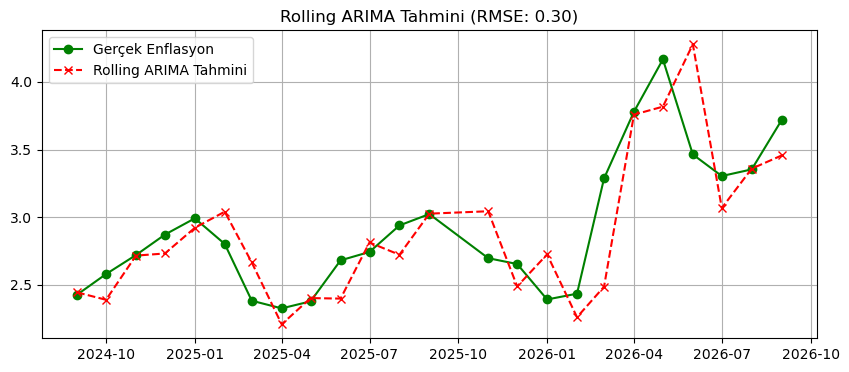

In [4]:
# Rolling Forecast (Her ay yeni veriyi görüp 1 ay sonrasını tahmin etme)
history = list(train)
predictions_arima = []

for t in range(len(test)):
    model = ARIMA(history, order=(2, 1, 2))
    model_fit = model.fit()
    yhat = model_fit.forecast()[0] # Sadece 1 adım sonrasını tahmin et
    predictions_arima.append(yhat)
    history.append(test.iloc[t]) # Gerçekleşen veriyi hafızaya ekle

rmse_arima_rolling = root_mean_squared_error(test, predictions_arima)
print(f"Güncellenmiş (Rolling) ARIMA RMSE Hatası: {rmse_arima_rolling:.4f}")

plt.figure(figsize=(10, 4))
plt.plot(test.index, test, label='Gerçek Enflasyon', color='green', marker='o')
plt.plot(test.index, predictions_arima, label='Rolling ARIMA Tahmini', color='red', linestyle='--', marker='x')
plt.title(f'Rolling ARIMA Tahmini (RMSE: {rmse_arima_rolling:.2f})')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
from pmdarima import auto_arima

# 1. Eğitim verisi üzerinde en düşük AIC skorunu veren (p, d, q) üçlüsünü bul
auto_model = auto_arima(train, seasonal=False, trace=True, error_action='ignore', suppress_warnings=True)
best_order = auto_model.order
print(f"\nBulunan En İyi (p, d, q): {best_order}")

# 2. Bulunan en iyi parametrelerle Rolling Forecast yap
history = list(train)
predictions_arima_opt = []

for t in range(len(test)):
    model = ARIMA(history, order=best_order)
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    predictions_arima_opt.append(yhat)
    history.append(test.iloc[t])

rmse_arima_opt = root_mean_squared_error(test, predictions_arima_opt)
print(f"Düz ARIMA (2,1,2) RMSE: {rmse_arima_rolling:.4f}")
print(f"Optimize ARIMA {best_order} RMSE: {rmse_arima_opt:.4f}")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=304.067, Time=0.35 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=372.628, Time=0.05 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=313.920, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=303.949, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=370.648, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=303.780, Time=0.11 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=304.297, Time=0.11 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=302.634, Time=0.17 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=302.909, Time=0.08 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=304.307, Time=0.14 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=302.424, Time=0.11 sec
 ARIMA(0,1,4)(0,0,0)[0] intercept   : AIC=304.259, Time=0.11 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=306.236, Time=0.44 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=300.437, Time=0.07 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=300.9

Optimize ARIMA RMSE : 0.3024
Düz XGBoost RMSE    : 0.4124


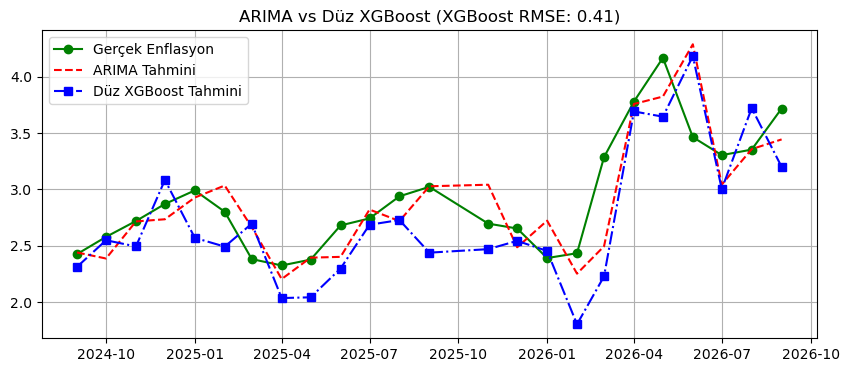

In [7]:
from xgboost import XGBRegressor

# 1. Zaman serisini XGBoost'un anlayacağı tabloya (Lag/Gecikme özelliklerine) çevir
df_ml = pd.DataFrame({'y': df['inflation']})
df_ml['lag_1'] = df_ml['y'].shift(1) # 1 ay önceki enflasyon
df_ml['lag_2'] = df_ml['y'].shift(2) # 2 ay önceki enflasyon
df_ml['lag_3'] = df_ml['y'].shift(3) # 3 ay önceki enflasyon
df_ml = df_ml.dropna()

# 2. Aynı şekilde son 24 ayı Test, öncesini Eğitim (Train) olarak ayır
train_ml = df_ml[:-24]
test_ml = df_ml[-24:]

X_train, y_train = train_ml.drop('y', axis=1), train_ml['y']
X_test, y_test = test_ml.drop('y', axis=1), test_ml['y']

# 3. Düz (Baseline) XGBoost Modelini Kur ve Eğit
model_xgb = XGBRegressor(random_state=42)
model_xgb.fit(X_train, y_train)

# 4. Tahmin yap ve RMSE hatasını hesapla
preds_xgb = model_xgb.predict(X_test)
rmse_xgb = root_mean_squared_error(y_test, preds_xgb)

print(f"Optimize ARIMA RMSE : {rmse_arima_opt:.4f}")
print(f"Düz XGBoost RMSE    : {rmse_xgb:.4f}")

# 5. Grafikle Kıyasla
plt.figure(figsize=(10, 4))
plt.plot(y_test.index, y_test, label='Gerçek Enflasyon', color='green', marker='o')
plt.plot(y_test.index, predictions_arima_opt, label='ARIMA Tahmini', color='red', linestyle='--')
plt.plot(y_test.index, preds_xgb, label='Düz XGBoost Tahmini', color='blue', linestyle='-.', marker='s')
plt.title(f'ARIMA vs Düz XGBoost (XGBoost RMSE: {rmse_xgb:.2f})')
plt.legend()
plt.grid(True)
plt.show()

Optimize ARIMA RMSE    : 0.3024
Düz XGBoost RMSE       : 0.4124
Optimize XGBoost RMSE  : 0.3083


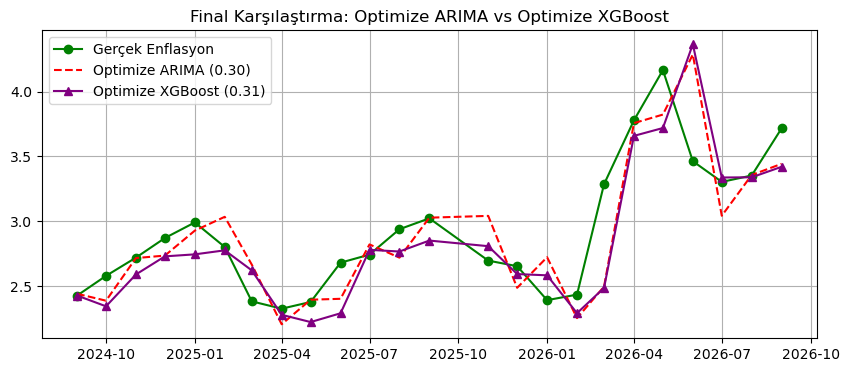

In [8]:
# 1. Daha zengin özellikler (Feature Engineering) oluştur
df_opt = pd.DataFrame({'y': df['inflation']})
df_opt['lag_1'] = df_opt['y'].shift(1)
df_opt['lag_2'] = df_opt['y'].shift(2)
df_opt['lag_3'] = df_opt['y'].shift(3)
df_opt['lag_12'] = df_opt['y'].shift(12) # Geçen yılın aynı ayı
df_opt['rolling_mean_3'] = df_opt['y'].shift(1).rolling(3).mean() # Son 3 ay ortalaması
df_opt['momentum'] = df_opt['lag_1'] - df_opt['lag_2'] # Enflasyonun artış/azalış ivmesi
df_opt['month'] = df_opt.index.month # Hangi ayda olduğumuz
df_opt = df_opt.dropna()

train_opt = df_opt[:-24]
test_opt = df_opt[-24:]

# 2. Rolling (Kaydırmalı) ve Optimize Edilmiş XGBoost
preds_xgb_opt = []

for i in range(len(test_opt)):
    # O ana kadar olan tüm veriyi al
    current_train = pd.concat([train_opt, test_opt.iloc[:i]])
    X_tr, y_tr = current_train.drop('y', axis=1), current_train['y']
    X_te = test_opt.iloc[[i]].drop('y', axis=1)
    
    # Overfitting'i önleyen optimize parametreler
    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )
    model.fit(X_tr, y_tr)
    preds_xgb_opt.append(model.predict(X_te)[0])

rmse_xgb_opt = root_mean_squared_error(test_opt['y'], preds_xgb_opt)

print(f"Optimize ARIMA RMSE    : {rmse_arima_opt:.4f}")
print(f"Düz XGBoost RMSE       : {rmse_xgb:.4f}")
print(f"Optimize XGBoost RMSE  : {rmse_xgb_opt:.4f}")

# 3. Final Karşılaştırma Grafiği
plt.figure(figsize=(10, 4))
plt.plot(test_opt.index, test_opt['y'], label='Gerçek Enflasyon', color='green', marker='o')
plt.plot(test_opt.index, predictions_arima_opt, label=f'Optimize ARIMA ({rmse_arima_opt:.2f})', color='red', linestyle='--')
plt.plot(test_opt.index, preds_xgb_opt, label=f'Optimize XGBoost ({rmse_xgb_opt:.2f})', color='purple', linestyle='-', marker='^')
plt.title('Final Karşılaştırma: Optimize ARIMA vs Optimize XGBoost')
plt.legend()
plt.grid(True)
plt.show()

1. Tek Değişkenli ARIMA RMSE      : 0.3024
2. Tek Değişkenli XGBoost RMSE    : 0.3083
3. Çok Değişkenli XGBoost RMSE    : 0.3032


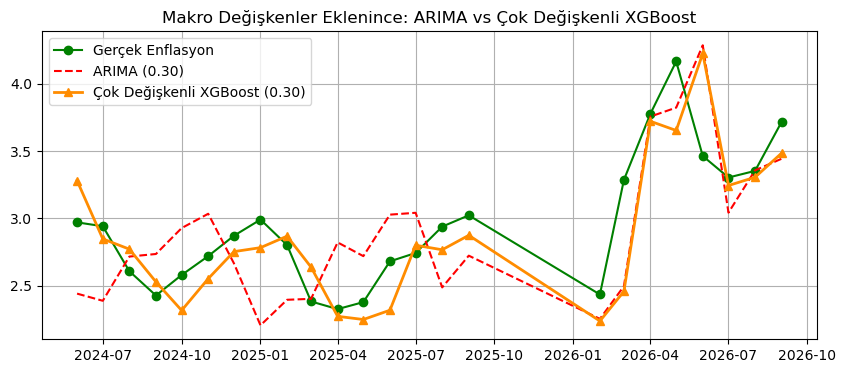

In [9]:
# 1. FRED'den Enflasyon (CPI), İşsizlik (UNRATE) ve FED Faizini (FEDFUNDS) aynı anda çek
symbols = ['CPIAUCSL', 'UNRATE', 'FEDFUNDS']
df_multi = web.DataReader(symbols, 'fred', start='2000-01-01')

# 2. Yıllık enflasyonu hesapla
df_multi['y'] = df_multi['CPIAUCSL'].pct_change(12) * 100

# 3. Özellikler (Features) - Veri sızıntısını önlemek için hepsini en az 1 ay gecikmeli (shift) alıyoruz
df_multi['lag_1'] = df_multi['y'].shift(1)
df_multi['lag_2'] = df_multi['y'].shift(2)
df_multi['lag_3'] = df_multi['y'].shift(3)
df_multi['rolling_mean_3'] = df_multi['y'].shift(1).rolling(3).mean()
df_multi['momentum'] = df_multi['lag_1'] - df_multi['lag_2']

# Yeni Makro Değişkenler (1 ay ve 3 ay önceki işsizlik ve faiz)
df_multi['unemp_lag1'] = df_multi['UNRATE'].shift(1)
df_multi['fed_lag1'] = df_multi['FEDFUNDS'].shift(1)
df_multi['fed_lag3'] = df_multi['FEDFUNDS'].shift(3) # Faizin etkisi gecikmeli gelir

df_multi = df_multi.drop(columns=['CPIAUCSL', 'UNRATE', 'FEDFUNDS']).dropna()

# 4. Eğitim ve Test ayrımı (Son 24 ay)
train_m = df_multi[:-24]
test_m = df_multi[-24:]

# 5. Çok Değişkenli (Multivariate) Rolling XGBoost
preds_xgb_multi = []

for i in range(len(test_m)):
    current_train = pd.concat([train_m, test_m.iloc[:i]])
    X_tr, y_tr = current_train.drop('y', axis=1), current_train['y']
    X_te = test_m.iloc[[i]].drop('y', axis=1)
    
    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )
    model.fit(X_tr, y_tr)
    preds_xgb_multi.append(model.predict(X_te)[0])

rmse_xgb_multi = root_mean_squared_error(test_m['y'], preds_xgb_multi)

print(f"1. Tek Değişkenli ARIMA RMSE      : {rmse_arima_opt:.4f}")
print(f"2. Tek Değişkenli XGBoost RMSE    : {rmse_xgb_opt:.4f}")
print(f"3. Çok Değişkenli XGBoost RMSE    : {rmse_xgb_multi:.4f}")

# 6. Sonuç Grafiği
plt.figure(figsize=(10, 4))
plt.plot(test_m.index, test_m['y'], label='Gerçek Enflasyon', color='green', marker='o')
plt.plot(test_m.index, predictions_arima_opt, label=f'ARIMA ({rmse_arima_opt:.2f})', color='red', linestyle='--')
plt.plot(test_m.index, preds_xgb_multi, label=f'Çok Değişkenli XGBoost ({rmse_xgb_multi:.2f})', color='darkorange', linewidth=2, marker='^')
plt.title('Makro Değişkenler Eklenince: ARIMA vs Çok Değişkenli XGBoost')
plt.legend()
plt.grid(True)
plt.show()

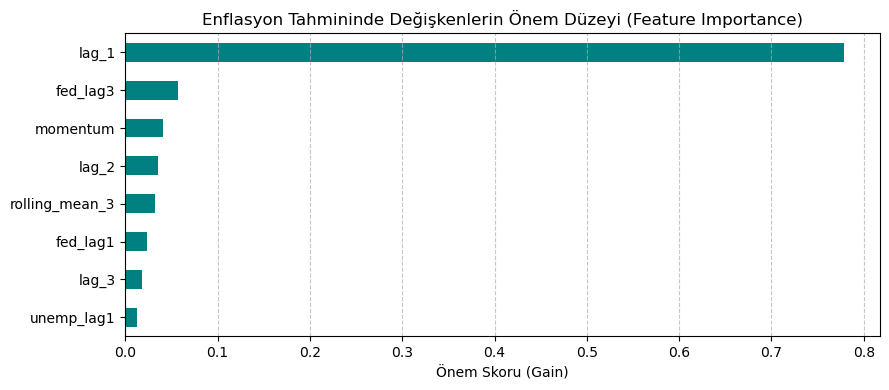

In [10]:
# 1. Son eğitilen Çok Değişkenli XGBoost modelinden Özellik Önemlerini (Feature Importance) al
importances = pd.Series(model.feature_importances_, index=X_tr.columns).sort_values(ascending=True)

# 2. Yatay Bar Grafiği ile Görselleştir
plt.figure(figsize=(9, 4))
importances.plot(kind='barh', color='teal')
plt.title('Enflasyon Tahmininde Değişkenlerin Önem Düzeyi (Feature Importance)')
plt.xlabel('Önem Skoru (Gain)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()